# Final holdout evaluation (April 2016 - September 2026)

Runs the **frozen** strategy in `config/frozen_strategy.json` exactly once. `authorize_final` checks the SHA-256 lock, refuses a different config, and appends this run to `results/final_runs.jsonl`. Small result tables and the chart go to `results/` (committed); per-trade tables to `outputs/final/` (ignored).

In [1]:
acknowledge_reselection = False
note = "final evaluation"

In [2]:
# Parameters
acknowledge_reselection = True
note = "Submitted strategy (P1_top50__R1). The holdout was used once before by the AI-run demonstration (results/demo_run); this strategy was selected by pre-registered rules on development data only."


In [3]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown, Image
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'quantlab').is_dir())
sys.path.insert(0, str(root))
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
from quantlab import protocol
from quantlab.experiment import run_final
cfg = json.loads(protocol.FROZEN_CONFIG.read_text())
auth = protocol.authorize_final(cfg, acknowledge_reselection=acknowledge_reselection, note=note)
print(auth.config_sha256, 'prior final runs:', auth.prior_final_runs)

f06421a68f05a4f6fbe7bab9abaa57786485cb0b11f7147c25134eedc3902a93 prior final runs: 2


In [4]:
fin = run_final(cfg, auth)
print(json.dumps(fin['summary'], indent=1, default=str))

[prepare:final] 2,071,060 panel rows, 1,795,256 eligible, 35s


{
 "experiment_id": "P1_top50__R1-f06421a6",
 "mode": "final",
 "config_sha256": "f06421a68f05a4f6fbe7bab9abaa57786485cb0b11f7147c25134eedc3902a93",
 "authorized_at": "2026-11-13T06:14:43+00:00",
 "prior_final_runs": 2,
 "reselection_acknowledged": true,
 "test_window": "2016-04-01 .. 2026-09-30",
 "delisting_policy": "settle_at_maturity",
 "final_value": 3883635.08721076,
 "benchmark_final_value": 4402746.776270891,
 "excess_final_value": -519111.6890601306,
 "beat_benchmark": false,
 "CAGR": 0.13794107389327626,
 "benchmark_CAGR": 0.1516195212753213,
 "Sharpe": 0.7018533394516553,
 "benchmark_Sharpe": 0.772500797137751,
 "max_drawdown": -0.3658802942883044,
 "benchmark_max_drawdown": -0.3379046158626988,
 "test_mean_rank_IC": 0.03589989603534879,
 "audit_checks_passed": "19/19",
 "integrity_events_in_test": {
  "unclassified": 1861,
  "bad_print": 585,
  "split": 128,
  "level_shift": 57
 },
 "integrity_events_touching_held_lots": {
  "unclassified": 15,
  "split": 9,
  "bad_print": 

## Required comparison: strategy vs $1,000,000 in ^SP500TR at the first test close

,strategy,S&P 500 TR
start,2016-03-31,2016-03-31
end,2026-09-30,2026-09-30
final_value,3883635.087211,4402746.776271
total_return,2.883635,3.402747
CAGR,0.137941,0.15162
max_drawdown,-0.36588,-0.337905
max_drawdown_date,2020-03-23,2020-03-23
annualized_volatility,0.179384,0.178178
Sharpe,0.701853,0.772501


beta                 0.865
tracking_error       0.095
information_ratio   -0.124
correlation          0.859
dtype: float64

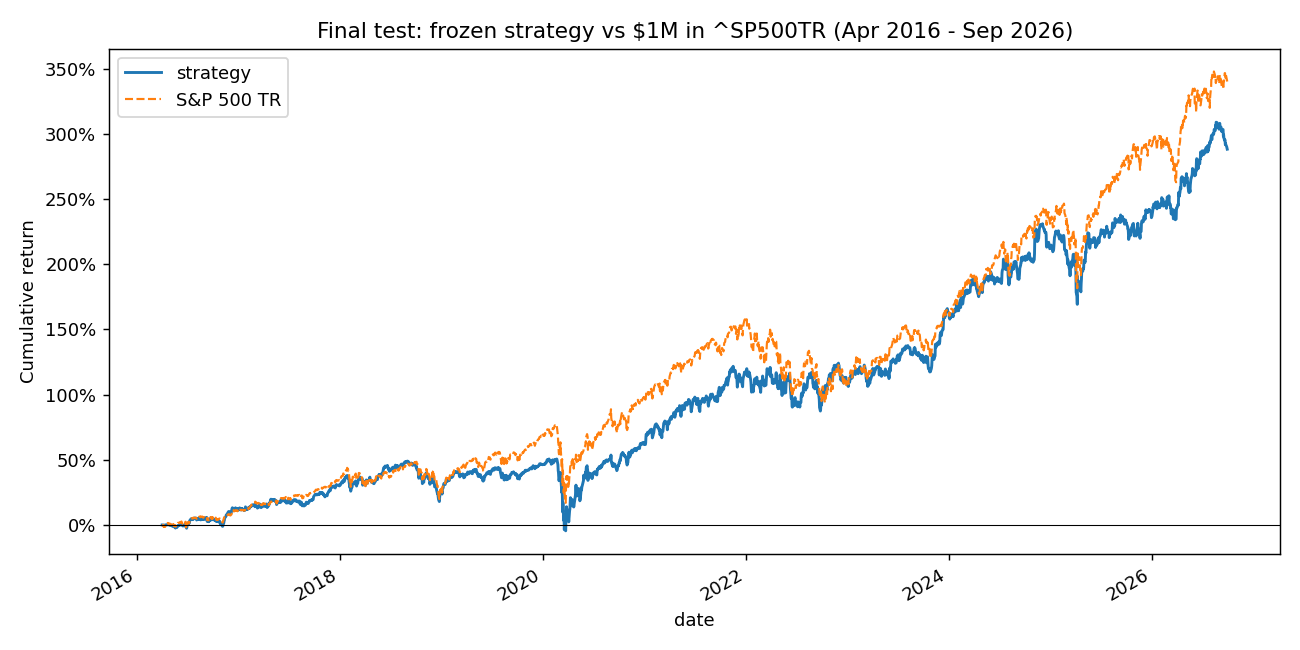

In [5]:
display(fin['performance'])
display(fin['relative'].round(3))
display(Image(filename=str(root / 'results' / 'cumulative_return.png')))

## Accounting and timing audit of the final run

In [6]:
display(fin['audit'])
assert fin['audit'].passed.all()

,check,passed,detail
0,cash = initial + cumulative fill cash changes,True,max abs error 2.24e-08
1,cash never negative,True,min cash 54211.835632
2,nav = cash + holdings,True,
3,holdings = units x last observed quote (indepe...,True,max abs error 1.40e-09
4,units never negative,True,
5,stale settlements use the last observed quote ...,True,
6,stale settlements happen at/after maturity,True,
7,every buy fills on the session after its signal,True,violations 0
8,buy price = that session's close,True,
9,same-day buys <= cash at the signal close (no ...,True,


## Sensitivity: data repairs, frozen-lot write-off, and costs

In [7]:
display(fin['sensitivity'][['final_value','CAGR','max_drawdown','Sharpe']])

,final_value,CAGR,max_drawdown,Sharpe
"primary (repaired prices, settle_at_maturity)",3883635.087211,0.137941,-0.36588,0.701853
frozen lots written to zero (lower bound),3860476.602316,0.137293,-0.36588,0.698643
prices as delivered (no split/level repair),3967661.54108,0.140263,-0.366561,0.71265
all breaks neutralized,3877764.59987,0.137777,-0.365881,0.701208
delisting policy: freeze,3382708.944061,0.123073,-0.353174,0.667251
fees 0 bps,4035992.365299,0.142119,-0.365488,0.722338
fees 25 bps,3329598.049683,0.121381,-0.373809,0.619891


## Prediction quality on completed test labels

In [8]:
display(fin['prediction'])
display(fin['prediction_by_year'].round(4))

dates                      603.000000
mean_rank_IC                 0.035900
IC_std                       0.135050
IC_hit_rate                  0.618574
IC_tstat_blocks              2.374342
top_minus_bottom_decile      0.008637
dtype: float64

,dates,mean_rank_IC,IC_std,IC_hit_rate,IC_tstat_blocks,top_minus_bottom_decile
year,,,,,,
2016,45.0,-0.0610,0.1056,0.3111,-0.8084,-0.0234
2017,59.0,0.0439,0.0525,0.7797,2.9835,0.0086
2018,59.0,0.0333,0.0721,0.6441,1.0210,0.0172
2019,59.0,0.0595,0.0929,0.7458,2.2659,0.0192
2020,59.0,-0.1009,0.1631,0.3729,-1.8155,-0.1009
2021,57.0,0.1812,0.0907,0.9825,6.1946,0.1477
2022,60.0,0.1105,0.1579,0.6833,1.8894,0.0667
2023,59.0,0.0798,0.1235,0.6949,1.8822,0.0238
2024,59.0,0.0235,0.1053,0.5424,0.7532,0.0044


## Portfolio diagnostics and data incidents touching held lots

In [9]:
display(fin['diagnostics'].round(4))
display(fin['touched'].groupby('kind').size())
display(fin['touched'].sort_values('date').head(30))

average_cash_fraction            0.0863
fees                         78507.0275
turnover_x_avg_nav              38.7147
lots_opened                  27181.0000
lots_closed                  26531.0000
lot_win_rate                     0.5756
mean_lot_net_return              0.0401
open_lots_at_end               650.0000
frozen_lots_at_end               4.0000
max_frozen_value_fraction        0.0348
rejected_orders                  5.0000
avg_names_held_proxy           637.3095
dtype: float64

kind
bad_print        8
split            9
unclassified    15
dtype: int64

,symbol,date,prev_date,confirm_date,gross,pre_price,post_price,pre_close,dv_day_ratio,kind,ratio,segment_quotes,lot_id,entry_date,exit_date,units,state
2196,KDP,2018-07-10,2018-07-09,2018-07-17,6.924460,2.780000,19.25,19.91,1.528634,split,7.000000,0,5538,2018-05-21,2018-08-20,77.368874,closed
2198,KDP,2018-07-10,2018-07-09,2018-07-17,6.924460,2.780000,19.25,19.91,1.528634,split,7.000000,0,5670,2018-06-11,2018-09-10,110.639813,closed
2197,KDP,2018-07-10,2018-07-09,2018-07-17,6.924460,2.780000,19.25,19.91,1.528634,split,7.000000,0,5633,2018-06-04,2018-09-04,101.788309,closed
2195,KDP,2018-07-10,2018-07-09,2018-07-17,6.924460,2.780000,19.25,19.91,1.528634,split,7.000000,0,5483,2018-05-14,2018-08-13,91.007882,closed
2705,NMRK,2020-03-18,2020-03-17,2020-03-25,0.545662,4.380000,2.39,4.58,0.898756,bad_print,NaN,1,9776,2020-01-13,2020-04-13,194.399024,closed
2704,NMRK,2020-03-18,2020-03-17,2020-03-25,0.545662,4.380000,2.39,4.58,0.898756,bad_print,NaN,1,9737,2020-01-06,2020-04-06,182.711866,closed
2703,NMRK,2020-03-18,2020-03-17,2020-03-25,0.545662,4.380000,2.39,4.58,0.898756,bad_print,NaN,1,9696,2019-12-30,2020-03-30,115.990377,closed
2708,NMRK,2020-03-18,2020-03-17,2020-03-25,0.545662,4.380000,2.39,4.58,0.898756,bad_print,NaN,1,9928,2020-02-03,2020-05-04,200.018596,closed
2709,NMRK,2020-03-18,2020-03-17,2020-03-25,0.545662,4.380000,2.39,4.58,0.898756,bad_print,NaN,1,10049,2020-02-18,2020-05-18,215.236001,closed
2710,NMRK,2020-03-18,2020-03-17,2020-03-25,0.545662,4.380000,2.39,4.58,0.898756,bad_print,NaN,1,10131,2020-03-02,2020-06-01,215.205839,closed
